# 01. Inspecting the Data & Splitting it Safely
**Project 26:** Card Fraud Triage  
**Team ID:** T047 (Section A)
**Lead:** Ritik Ranjan  

---
### What we are doing in this notebook:
1. Load `creditcard.csv` and look at its shape.
2. Check if there are any missing values.
3. Check how many normal vs fraud transactions we have.
4. Look at the `Time` and `Amount` columns.
5. Drop duplicate rows.
6. Split the data by time into **Train (60%)**, **Validation (20%)**, and **Test (20%)**.
7. **Important Rule:** Remove fraud from the training set so our model only learns normal spending!
8. Save the clean files in `data/processed/`.

### Step 1: Import basic libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


### Step 2: Load the raw dataset

In [2]:
# Load the dataset
file_path = '../data/raw/creditcard.csv'
if not os.path.exists(file_path):
    file_path = 'data/raw/creditcard.csv'

df = pd.read_csv(file_path)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Step 3: Check for missing values

In [3]:
# Check for any null or missing values
print("Total missing values in dataset:", df.isnull().sum().sum())
df.info()

Total missing values in dataset: 0
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null 

### Step 4: Check normal vs fraud counts (Class Imbalance)

Class
0    284315
1       492
Name: count, dtype: int64
Fraud is only 0.1727% of all transactions!


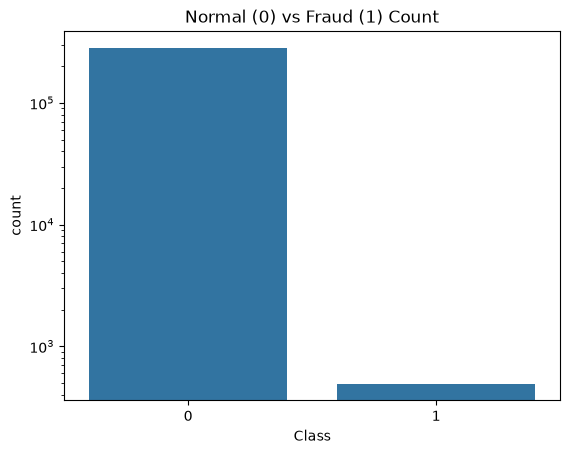

In [4]:
# Count normal (0) vs fraud (1)
print(df['Class'].value_counts())

fraud_percent = (df['Class'].sum() / len(df)) * 100
print(f"Fraud is only {fraud_percent:.4f}% of all transactions!")

# Simple bar chart
sns.countplot(x='Class', data=df)
plt.title("Normal (0) vs Fraud (1) Count")
plt.yscale('log')
plt.show()

### Step 5: Check Time and Amount columns

In [5]:
# Time is in seconds from the start
total_seconds = df['Time'].max()
total_hours = total_seconds / 3600
print(f"Total time recorded: {total_hours:.2f} hours (about {total_hours / 24:.1f} days)")

# Summary of Amount
print("\nAmount summary in Euros (€):")
print(df['Amount'].describe())

Total time recorded: 48.00 hours (about 2.0 days)

Amount summary in Euros (€):
count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


### Step 6: Find and remove duplicate rows

In [6]:
# Count duplicate rows
num_duplicates = df.duplicated().sum()
print("Number of duplicate rows found:", num_duplicates)

# Drop duplicates
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Number of duplicate rows found: 1081


Shape after dropping duplicates: (283726, 31)


### Step 7: Split data into Train, Validation, and Test
We split by time:
- First 60% of time -> Train
- Next 20% of time  -> Validation
- Last 20% of time  -> Test

**Golden Rule:** We drop fraud transactions from the training set, because our anomaly detection model should only learn normal customer behavior!

In [7]:
# Sort by Time to make sure it is chronological
df = df.sort_values(by='Time').reset_index(drop=True)

n = len(df)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

train_raw = df.iloc[:train_end]
val_data = df.iloc[train_end:val_end]
test_data = df.iloc[val_end:]

# Filter train set to normal only (Class == 0)
train_legit = train_raw[train_raw['Class'] == 0]

print("Train set (normal only):", train_legit.shape)
print("Validation set (mixed): ", val_data.shape, "with frauds:", (val_data['Class'] == 1).sum())
print("Test set (mixed):       ", test_data.shape, "with frauds:", (test_data['Class'] == 1).sum())

Train set (normal only): (169893, 31)
Validation set (mixed):  (56745, 31) with frauds: 57
Test set (mixed):        (56746, 31) with frauds: 74


### Step 8: Save clean files

In [8]:
# Save the files
out_dir = '../data/processed'
if not os.path.exists(out_dir):
    out_dir = 'data/processed'
os.makedirs(out_dir, exist_ok=True)

train_legit.to_csv(os.path.join(out_dir, 'train_legit.csv'), index=False)
val_data.to_csv(os.path.join(out_dir, 'val_mixed.csv'), index=False)
test_data.to_csv(os.path.join(out_dir, 'test_mixed.csv'), index=False)

print("Saved train_legit.csv, val_mixed.csv, and test_mixed.csv in data/processed!")

Saved train_legit.csv, val_mixed.csv, and test_mixed.csv in data/processed!
